In [31]:
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    auc
)
from sklearn.metrics import confusion_matrix

In [22]:
# read in data
df = pd.read_csv("weatherAUS.csv")
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


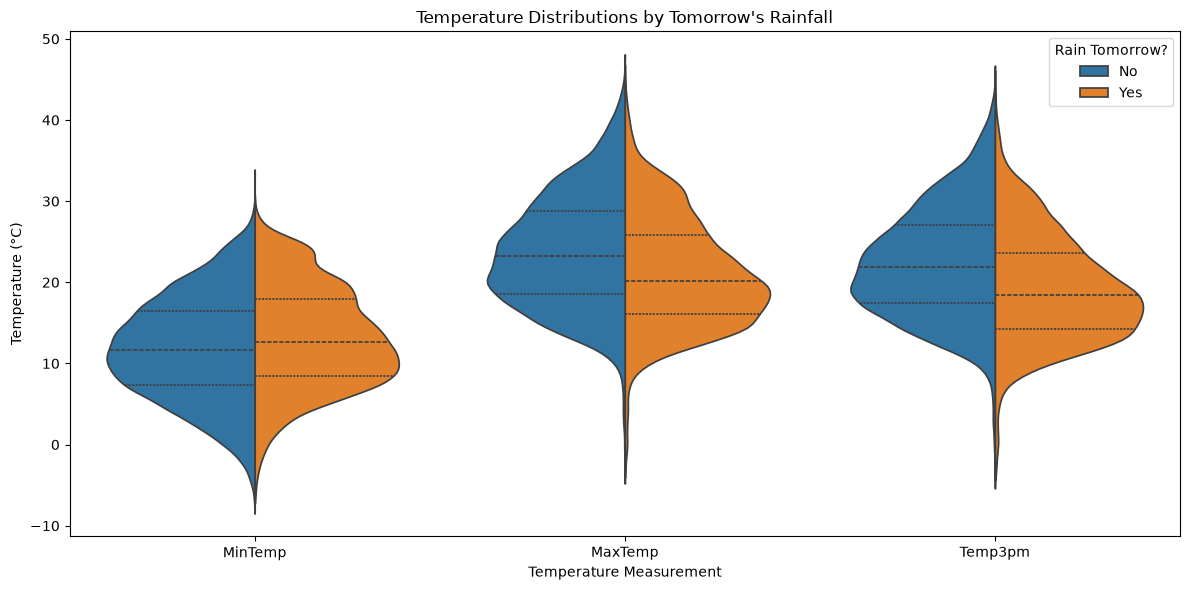

In [23]:
#temp dist by rainfall at 3pm 
temp_df = df.dropna(
    subset=["RainTomorrow", "MinTemp", "MaxTemp", "Temp3pm"]
).copy()

# Convert from wide format to long format for plotting
temp_long = temp_df.melt(
    id_vars="RainTomorrow",
    value_vars=["MinTemp", "MaxTemp", "Temp3pm"],
    var_name="TemperatureType",
    value_name="Temperature"
)

plt.figure(figsize=(12, 6))

sns.violinplot(
    data=temp_long,
    x="TemperatureType",
    y="Temperature",
    hue="RainTomorrow",
    hue_order=["No", "Yes"],
    split=True,
    inner="quartile",
    cut=0
)

plt.title("Temperature Distributions by Tomorrow's Rainfall")
plt.xlabel("Temperature Measurement")
plt.ylabel("Temperature (°C)")
plt.legend(title="Rain Tomorrow?")
plt.tight_layout()
plt.show()

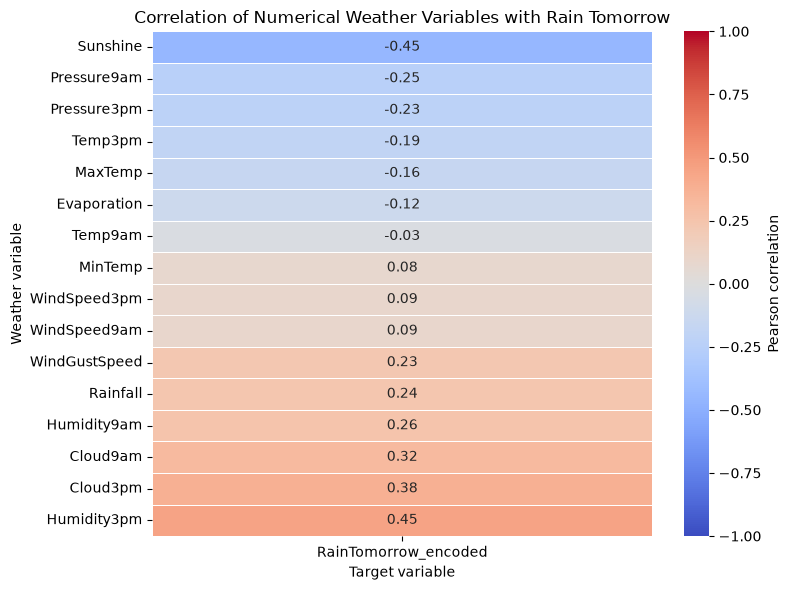

In [ ]:
#heatmap correlations 
corr_df = df.dropna(subset=["RainTomorrow"]).copy()

# Encode target: No = 0, Yes = 1
corr_df["RainTomorrow_encoded"] = (
    corr_df["RainTomorrow"].map({"No": 0, "Yes": 1})
)

#numerical columns
numeric_cols = corr_df.select_dtypes(include=np.number).columns.tolist()

#correlations with target
target_corr = (
    corr_df[numeric_cols]
    .corr(numeric_only=True)["RainTomorrow_encoded"]
    .drop("RainTomorrow_encoded")
    .dropna()
    .sort_values() 
)

plt.figure(figsize=(8, max(6, len(target_corr) * 0.35)))

sns.heatmap(
    target_corr.to_frame(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Pearson correlation"}
)

plt.title("Correlation of Numerical Weather Variables with Rain Tomorrow")
plt.xlabel("Target Variable")
plt.ylabel("Weather Variable")
plt.tight_layout()
plt.show()

In [5]:
# dropping rows with no target variable
df = df.dropna(subset=["RainTomorrow"]).reset_index(drop=True)
print(f"rows after dropping unlabeled: {len(df)}")

X = df.drop(columns=["RainTomorrow"])
y = df["RainTomorrow"]

# using stratify to make sure class representation is similar throughout all sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.4, shuffle=True, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_val, y_val, test_size=0.5, shuffle=True, stratify=y_val, random_state=42)

print(X_train.shape, X_val.shape, X_test.shape)

rows after dropping unlabeled: 142193
(85315, 22) (28439, 22) (28439, 22)


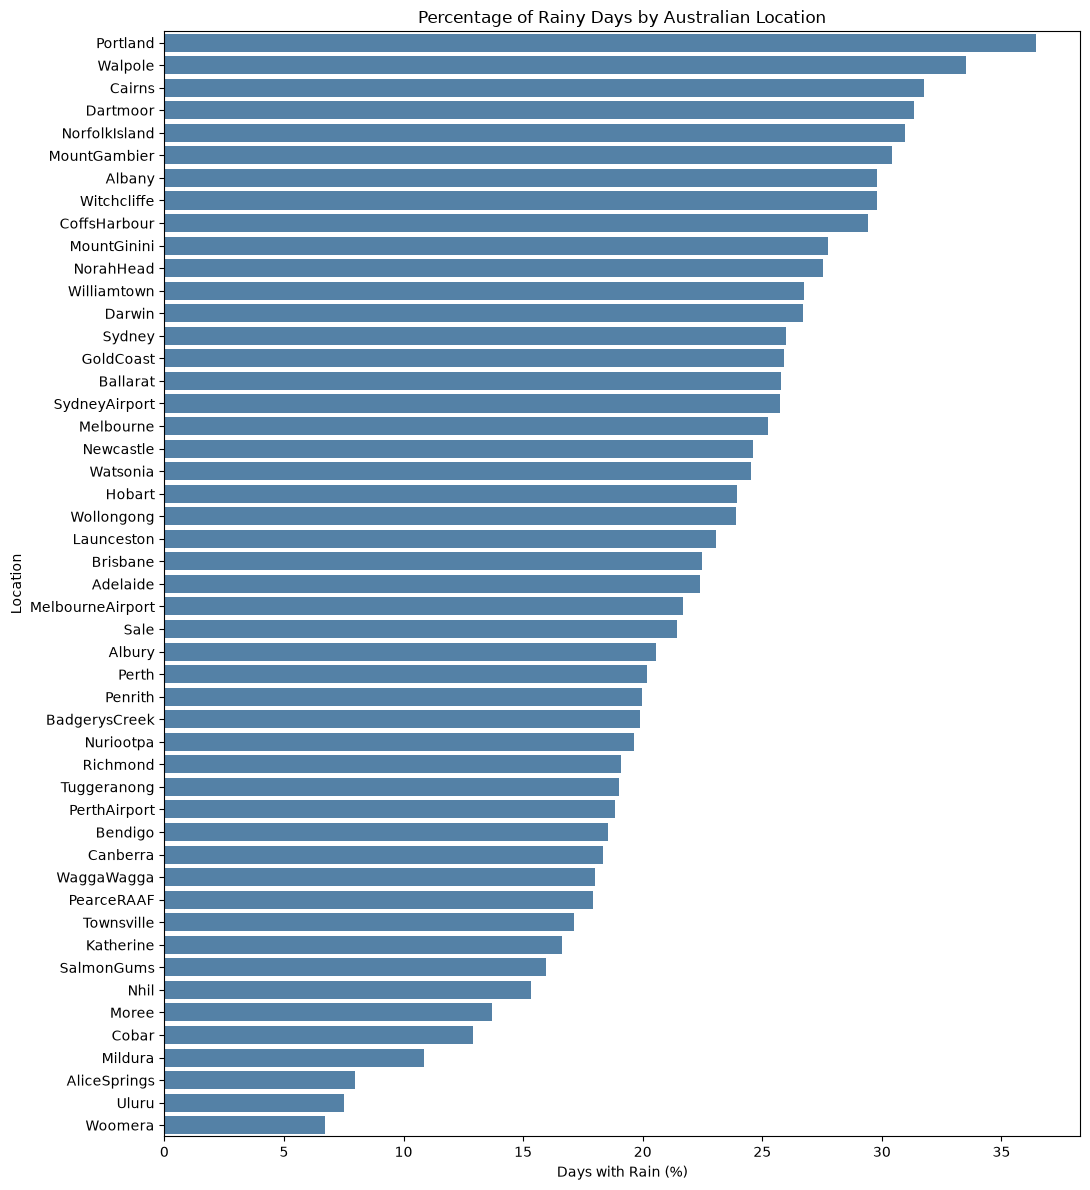

In [ ]:
# visualization prior to pre-processing (intial exploratory)
location_df = df.dropna(subset=["Location", "RainToday"]).copy()

# calc percent of obs with rain for each location
location_rain = (
    location_df.assign(Rainy=location_df["RainToday"].eq("Yes"))
    .groupby("Location")["Rainy"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 12))

sns.barplot(
    x=location_rain.values,
    y=location_rain.index,
    color="steelblue"
)

plt.title("Percentage of Rainy Days by Australian Location")
plt.xlabel("Days with Rain (%)")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

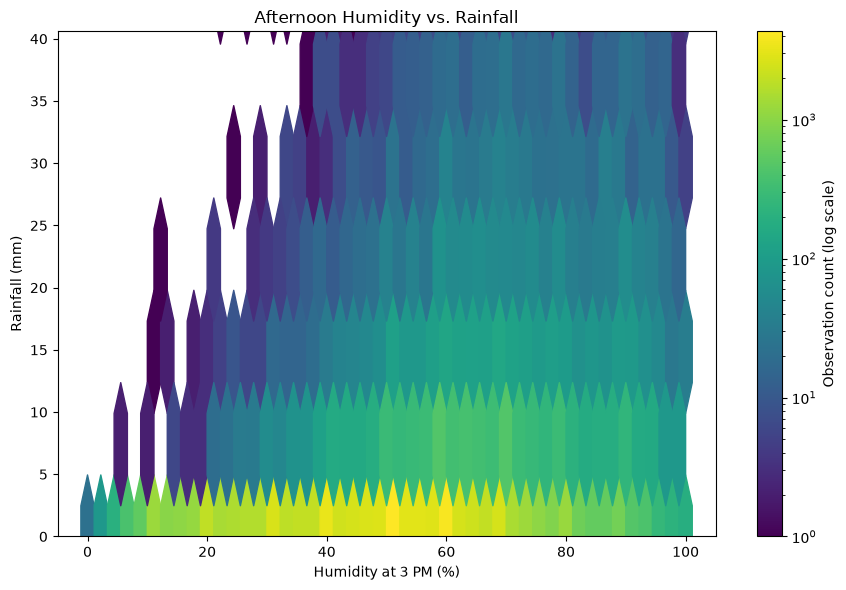

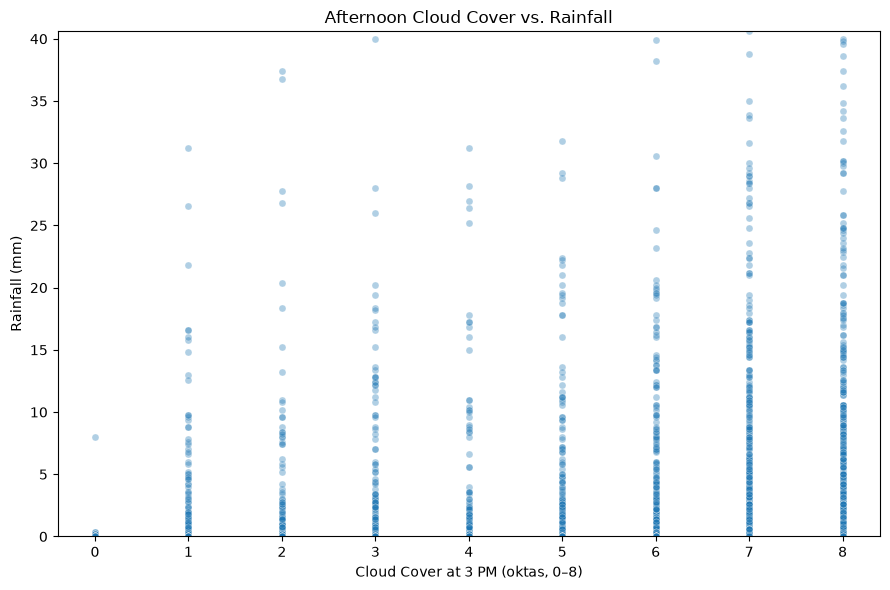

In [ ]:
# rain vs humidity and cloud cover
rain_df = df.dropna(
    subset=["Humidity3pm", "Cloud3pm", "Rainfall"]
).copy()

#  humidity versus rainfall
plt.figure(figsize=(9, 6))

plt.hexbin(
    rain_df["Humidity3pm"],
    rain_df["Rainfall"],
    gridsize=45,
    mincnt=1,
    bins="log",
    cmap="viridis"
)

plt.colorbar(label="Observation count (log scale)")
plt.title("Afternoon Humidity vs. Rainfall")
plt.xlabel("Humidity at 3 PM (%)")
plt.ylabel("Rainfall (mm)")
plt.ylim(0, rain_df["Rainfall"].quantile(0.99))
plt.tight_layout()
plt.show()

# cloud cover versus rainfall
# sample rows to reduce overplotting
# might not be worthwhile since it's not the easist to read 
sample_df = rain_df.sample(
    n=min(5000, len(rain_df)),
    random_state=42
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=sample_df,
    x="Cloud3pm",
    y="Rainfall",
    alpha=0.35,
    s=25
)

plt.title("Afternoon Cloud Cover vs. Rainfall")
plt.xlabel("Cloud Cover at 3 PM (oktas, 0–8)")
plt.ylabel("Rainfall (mm)")
plt.ylim(0, rain_df["Rainfall"].quantile(0.99))
plt.tight_layout()
plt.show()


In [7]:
# convert date to month
# trying to use cyclic encoding too to capture seasonality
for df in (X_train, X_val, X_test):
    df['Date'] = pd.to_datetime(df['Date'])
    df['Month'] = df['Date'].dt.month
    df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
    df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)

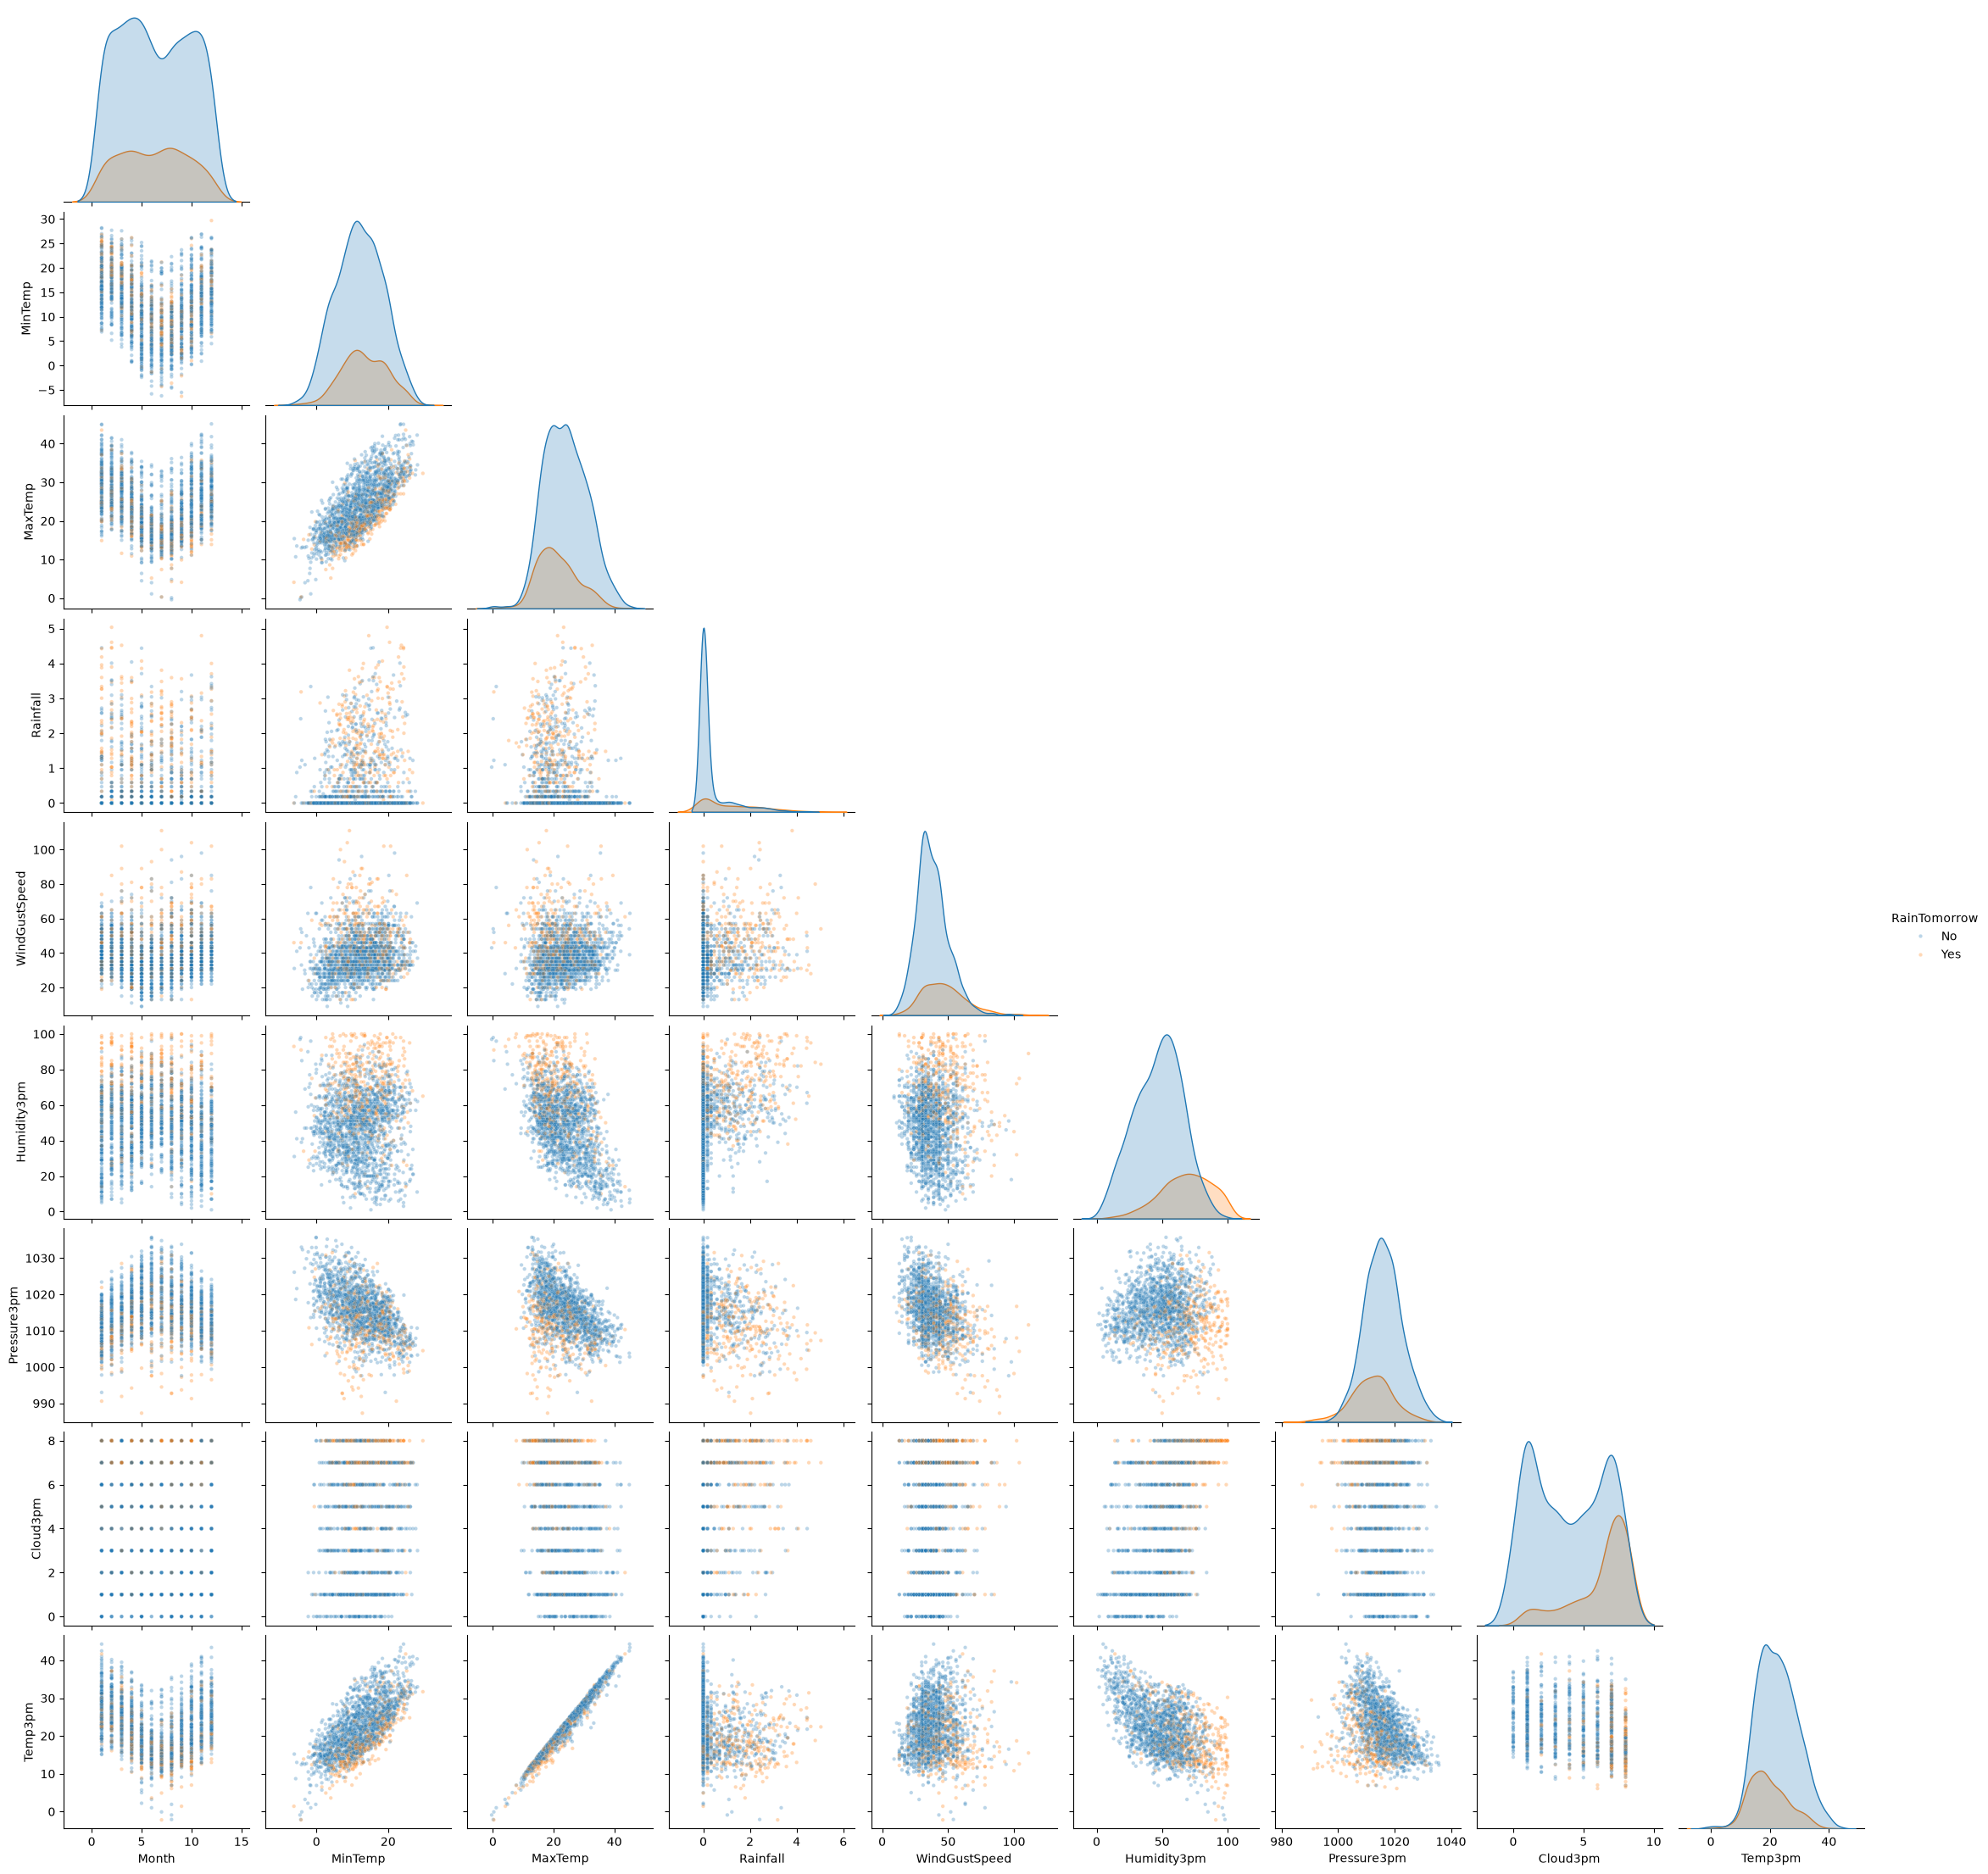

In [8]:
# numeric columns
num_cols = ["Month", "MinTemp", "MaxTemp", "Rainfall", "WindGustSpeed", "Humidity3pm", "Pressure3pm", "Cloud3pm", "Temp3pm"]

# build paired plots from training data
paired_train = X_train[num_cols].copy()
paired_train["Rainfall"] = np.log1p(paired_train["Rainfall"])
paired_train["RainTomorrow"] = y_train.values

sns.pairplot(
    paired_train.sample(min(2000, len(paired_train)), random_state=0),
    hue="RainTomorrow",
    corner=True,          
    diag_kind="kde",      
    plot_kws={"alpha": 0.3, "s": 10},
)
plt.show()

In [9]:
# check on Missing Data
num_cols = ["Month", "MinTemp", "MaxTemp", "Rainfall", "WindGustSpeed", "Humidity3pm", "Pressure3pm", "Cloud3pm", "Temp3pm"]
other_cols = ["Location", "WindGustDir", "RainToday"]
cols = num_cols + other_cols

na_counts = X_train[cols].isna().sum()
na_pct = (X_train[cols].isna().mean() * 100).round(2)
na_summary = pd.DataFrame({"n_missing": na_counts, "pct_missing": na_pct})

na_summary

# Cloud3pm seems to be missing a lot of data

,n_missing,pct_missing
Month,0,0.00
MinTemp,384,0.45
MaxTemp,189,0.22
Rainfall,825,0.97
WindGustSpeed,5566,6.52
Humidity3pm,2191,2.57
Pressure3pm,8372,9.81
Cloud3pm,34323,40.23
Temp3pm,1654,1.94
Location,0,0.00


In [10]:
# columns filled with the location median, falling back to the global median
fill_cols = ["Cloud3pm", "Pressure3pm", "WindGustSpeed", "Humidity3pm", "Temp3pm", "Rainfall", "MinTemp", "MaxTemp"]

# grab gobal medians and location specific medians
global_med = X_train[fill_cols].median()
loc_med = {c: X_train.groupby("Location")[c].median() for c in fill_cols}
rain_today_mode = X_train["RainToday"].mode()[0]

def impute(df):
    df = df.copy()

    # creating missing falg columns for the features that have the most missing data (there might be signal there)
    df["Cloud3pm_missing"] = df["Cloud3pm"].isna().astype(int)
    df["Pressure3pm_missing"] = df["Pressure3pm"].isna().astype(int)
    df["WindGust_missing"] = (df["WindGustSpeed"].isna() | df["WindGustDir"].isna()).astype(int)

    # attempting to use location specific median first, then global median
    for c in fill_cols:
        df[c] = df[c].fillna(df["Location"].map(loc_med[c]).fillna(global_med[c]))

    # categorical
    df["WindGustDir"] = df["WindGustDir"].fillna("Unknown")
    df["RainToday"] = df["RainToday"].fillna(rain_today_mode)
    return df

X_train = impute(X_train)
X_val = impute(X_val)
X_test = impute(X_test)

In [11]:
# standardizing numeric columns
#  numeric columns (excluding Month)
num_cols = ["MinTemp", "MaxTemp", "Rainfall", "WindGustSpeed", "Humidity3pm", "Pressure3pm", "Cloud3pm", "Temp3pm"]

X_train_std = X_train.copy()
X_val_std = X_val.copy()
X_test_std = X_test.copy()

# log transform on rainfall to compensate for heavy right skew
for df in (X_train_std, X_val_std, X_test_std):
    df["Rainfall"] = np.log1p(df["Rainfall"])

mean = X_train_std[num_cols].mean()
std = X_train_std[num_cols].std(ddof=0)

# standardize
for df in (X_train_std, X_val_std, X_test_std):
    df[num_cols] = (df[num_cols] - mean) / std

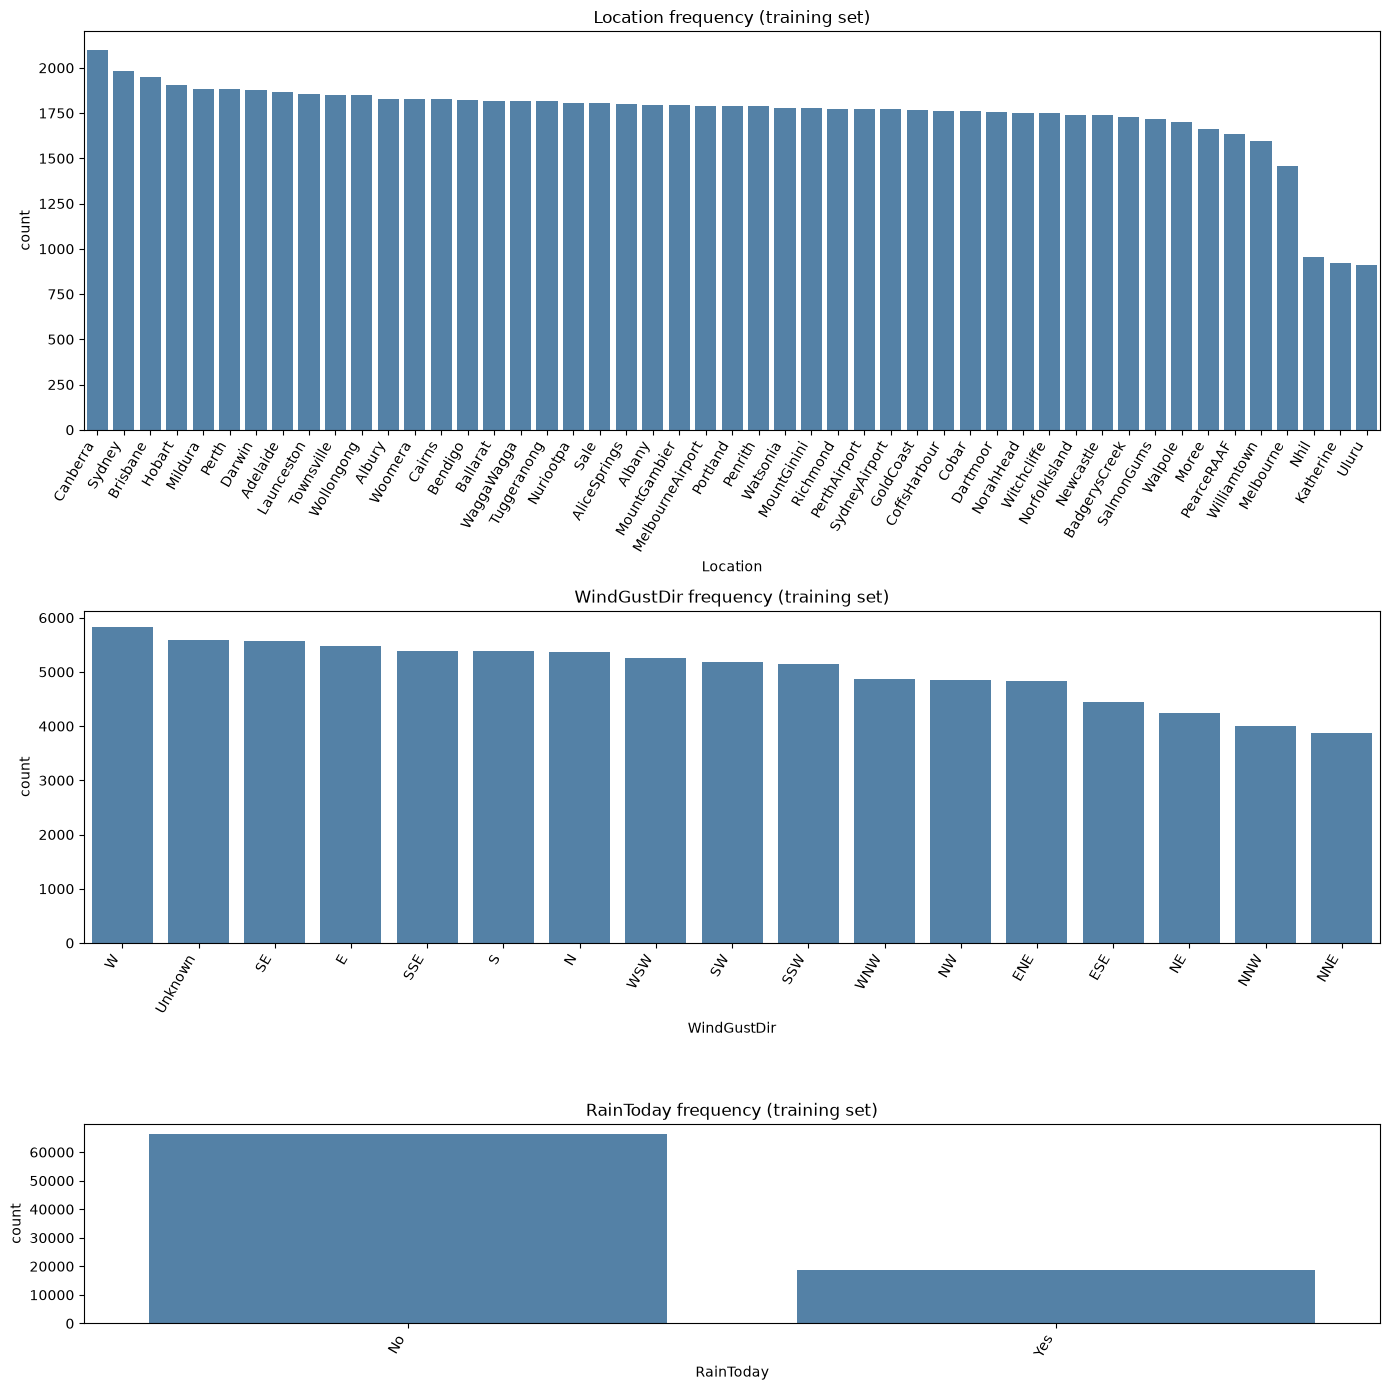

In [12]:
# categorical features 
# checking for representation accross each features
cat_cols = ["Location", "WindGustDir", "RainToday"]

fig, axes = plt.subplots(3, 1, figsize=(14, 14), gridspec_kw={"height_ratios": [1.2, 1, 0.6]})

for ax, col in zip(axes, cat_cols):
    counts = X_train[col].value_counts()
    sns.barplot(x=counts.index.astype(str), y=counts.values, ax=ax, color="steelblue")
    ax.set_title(f"{col} frequency (training set)")
    ax.set_ylabel("count")
    ax.tick_params(axis="x", rotation=60)
    for lbl in ax.get_xticklabels():
        lbl.set_ha("right")

plt.tight_layout()
plt.show()

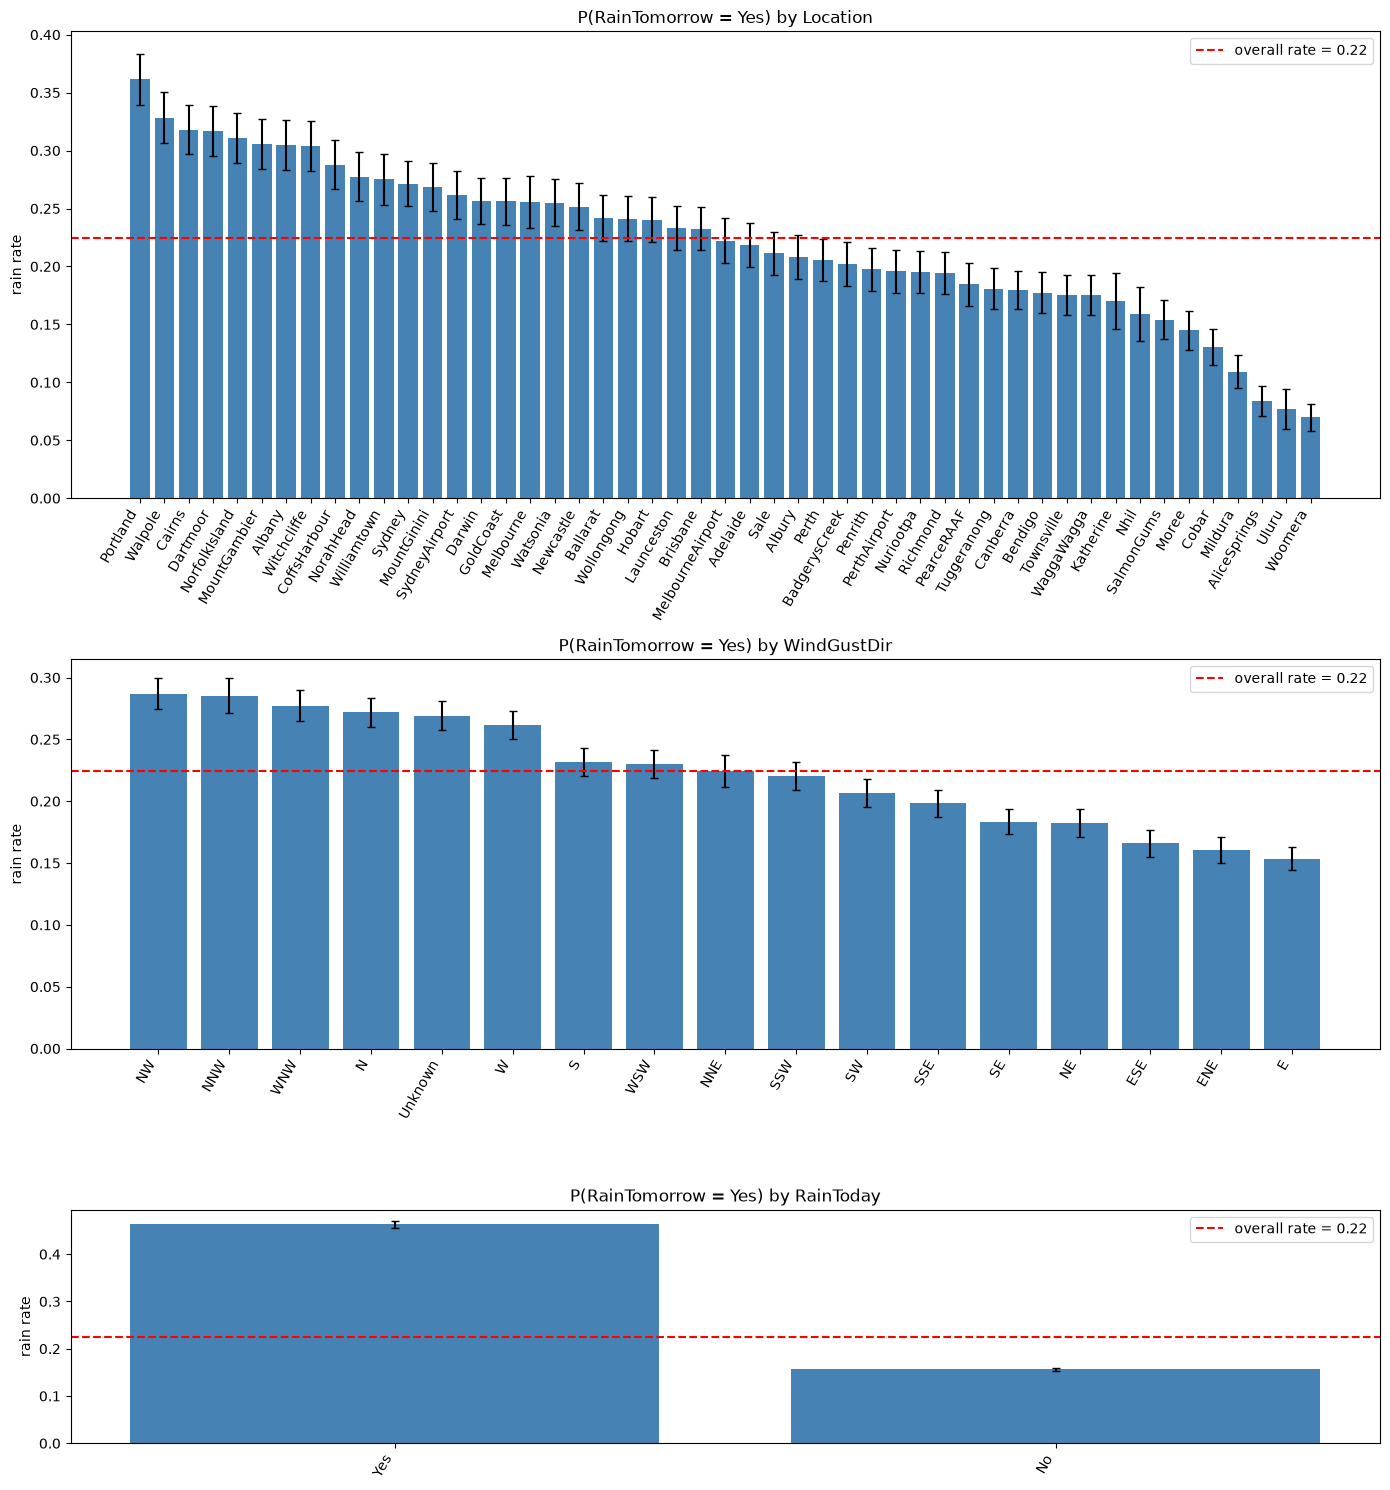

In [13]:
# checking if categorical features have a relationship with target variable
cat_cols = ["Location", "WindGustDir", "RainToday"]

temp = X_train[cat_cols].copy()
temp["RainTomorrow_num"] = (pd.Series(np.asarray(y_train)).astype(str).str.lower().isin(["yes", "1", "true"]).astype(int).values)
base_rate = temp["RainTomorrow_num"].mean()

fig, axes = plt.subplots(3, 1, figsize=(14, 15), gridspec_kw={"height_ratios": [1.2, 1, 0.6]})

for ax, col in zip(axes, cat_cols):
    g = (temp.groupby(col)["RainTomorrow_num"].agg(rate="mean", n="size").sort_values("rate", ascending=False))
    err = 1.96 * np.sqrt(g["rate"] * (1 - g["rate"]) / g["n"])
    ax.bar(g.index.astype(str), g["rate"], yerr=err, color="steelblue", capsize=3)
    ax.axhline(base_rate, color="red", ls="--", label=f"overall rate = {base_rate:.2f}")
    ax.set_title(f"P(RainTomorrow = Yes) by {col}")
    ax.set_ylabel("rain rate")
    ax.tick_params(axis="x", rotation=60)
    for lbl in ax.get_xticklabels():
        lbl.set_ha("right")
    ax.legend()

plt.tight_layout()
plt.show()

# it appears that different values within categorical variables show different rates of rain. For example, rain is much more
# likely in Portland than in Woomera

In [14]:
# one hot encoding categorical variables
# columns being used in model
num_cols = ["MinTemp", "MaxTemp", "Rainfall", "WindGustSpeed", "Humidity3pm", "Pressure3pm", "Cloud3pm", "Temp3pm"]
cyc_cols = ["Month_sin", "Month_cos"]
flag_cols = ["Cloud3pm_missing", "Pressure3pm_missing", "WindGust_missing"]
onehot_cols = ["Location", "WindGustDir"]
keep = num_cols + cyc_cols + flag_cols + ["RainToday"] + onehot_cols

# category lists from train
loc_cats = sorted(X_train["Location"].unique())
wind_dir_cats = sorted(X_train["WindGustDir"].unique())

def encode(df):
    df = df[keep].copy()
    df["RainToday"] = df["RainToday"].map({"No": 0, "Yes": 1}).astype(int)
    df["Location"] = pd.Categorical(df["Location"], categories=loc_cats)
    df["WindGustDir"] = pd.Categorical(df["WindGustDir"], categories=wind_dir_cats)
    return pd.get_dummies(df, columns=onehot_cols, dtype=int)

X_train_enc = encode(X_train_std)
X_val_enc = encode(X_val_std)
X_test_enc = encode(X_test_std)

label_map = {"No": 0, "Yes": 1}
y_train_enc = y_train.map(label_map).astype(int)
y_val_enc = y_val.map(label_map).astype(int)
y_test_enc = y_test.map(label_map).astype(int)

Model Building section

In [42]:
# naive model
# Baseline heuristic: predict RainTomorrow = RainToday
y_true = y_val_enc.to_numpy()
y_pred = X_val_enc["RainToday"].to_numpy()

# confusion matrix counts
tp = np.sum((y_pred == 1) & (y_true == 1))   
fp = np.sum((y_pred == 1) & (y_true == 0))   
fn = np.sum((y_pred == 0) & (y_true == 1))   
tn = np.sum((y_pred == 0) & (y_true == 0))   

accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)

print("Naive Model Metrics")
print(f"accuracy: {accuracy:.3f}")
print(f"precision: {precision:.3f}")
print(f"recall: {recall:.3f}")
print(f"f1: {f1:.3f}")

Naive Model Metrics
accuracy: 0.761
precision: 0.467
recall: 0.458
f1: 0.463


In [16]:
def build_model(num_features, learning_rate):
  """Build a TF logistic regression model using Keras.

  Args:
    num_features: The number of input features.
    learning_rate: The desired learning rate for SGD.

  Returns:
    model: A tf.keras model (graph).
  """
  tf.keras.backend.clear_session()
  tf.random.set_seed(0)

  # Logistic regression = a single Dense layer with a sigmoid output.
  model = tf.keras.Sequential()
  model.add(tf.keras.Input(shape=(num_features,)))   
  model.add(tf.keras.layers.Dense(
      units=1,                                        
      activation='sigmoid',                           
      use_bias=True,                                  
      kernel_initializer=tf.keras.initializers.Zeros(), 
      bias_initializer=tf.keras.initializers.Zeros(),
  ))

  # gradient descent
  optimizer = tf.keras.optimizers.SGD(learning_rate=learning_rate)

  # metrics
  model.compile(
      loss='binary_crossentropy',
      optimizer=optimizer,
      metrics=[
          tf.keras.metrics.BinaryAccuracy(name='accuracy'),   
          tf.keras.metrics.Precision(name='precision'),       
          tf.keras.metrics.Recall(name='recall'),             
          tf.keras.metrics.AUC(name='roc_auc'),
          tf.keras.metrics.AUC(curve='PR', name='pr_auc')
      ],
  )

  return model


Epoch 1/50
167/167 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8320 - loss: 0.4248 - pr_auc: 0.6236 - precision: 0.6835 - recall: 0.4667 - roc_auc: 0.8219 - val_accuracy: 0.8400 - val_loss: 0.3756 - val_pr_auc: 0.6745 - val_precision: 0.7162 - val_recall: 0.4746 - val_roc_auc: 0.8532
Epoch 2/50
167/167 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8373 - loss: 0.3761 - pr_auc: 0.6628 - precision: 0.7100 - recall: 0.4632 - roc_auc: 0.8511 - val_accuracy: 0.8419 - val_loss: 0.3680 - val_pr_auc: 0.6825 - val_precision: 0.7199 - val_recall: 0.4826 - val_roc_auc: 0.8564
Epoch 3/50
167/167 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8385 - loss: 0.3721 - pr_auc: 0.6683 - precision: 0.7123 - recall: 0.4692 - roc_auc: 0.8536 - val_accuracy: 0.8430 - val_loss: 0.3654 - val_pr_auc: 0.6864 - val_precision: 0.7214 - val_recall: 0.4881 - val_roc_auc: 0.8583
Epoch 4/50
167/167 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8395 - loss: 0.3703 - pr_auc: 0.6714 - precision: 0.7153 - recall: 0.

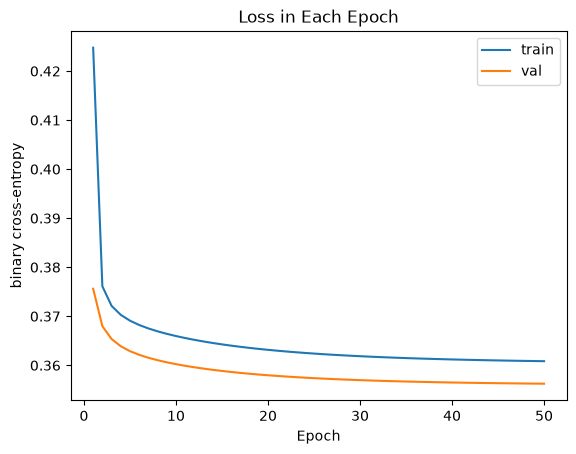

Validation metrics (logistic regression, TF):
accuracy   0.847
loss       0.356
pr_auc     0.701
precision  0.729
recall     0.507
roc_auc    0.866
f1         0.598


In [17]:
# Numpy arrays from the encoded data
Xtr = X_train_enc.to_numpy(dtype='float32')
Xva = X_val_enc.to_numpy(dtype='float32')
ytr = y_train_enc.to_numpy(dtype='float32')
yva = y_val_enc.to_numpy(dtype='float32')

# Build and compile model
model_tf = build_model(num_features=Xtr.shape[1], learning_rate=0.1)

# Fit the model
num_epochs = 50
history = model_tf.fit(
    x=Xtr,
    y=ytr,
    validation_data=(Xva, yva),
    epochs=num_epochs,
    batch_size=512,
    verbose=1,
)

# Plor Learning curve
plt.plot(range(1, num_epochs + 1), history.history['loss'], label='train')
plt.plot(range(1, num_epochs + 1), history.history['val_loss'], label='val')
plt.xlabel('Epoch')
plt.ylabel('binary cross-entropy')
plt.title('Loss in Each Epoch')
plt.legend()
plt.show()

# Validation metrics, straight from Keras
val_metrics = model_tf.evaluate(Xva, yva, batch_size=512, return_dict=True, verbose=0)
p, r = val_metrics['precision'], val_metrics['recall']
val_metrics['f1'] = 2 * p * r / (p + r) if (p + r) > 0 else 0.0  

print('Validation metrics (logistic regression, TF):')
for name, value in val_metrics.items():
    print(f'{name:10s} {value:.3f}')

In [18]:
# Evaluate the trained model on all three splits (threshold 0.5)
Xte = X_test_enc.to_numpy(dtype='float32')
yte = y_test_enc.to_numpy(dtype='float32')

results = {
    'train': model_tf.evaluate(Xtr, ytr, batch_size=512, return_dict=True, verbose=0),
    'val': model_tf.evaluate(Xva, yva, batch_size=512, return_dict=True, verbose=0),
    'test': model_tf.evaluate(Xte, yte, batch_size=512, return_dict=True, verbose=0),
}

table = pd.DataFrame(results).T
table['f1'] = 2 * table['precision'] * table['recall'] / (table['precision'] + table['recall'])

print(table.round(3))

# model shows really good generalization ability. All accuracy metrics are very similar across all data sets

       accuracy   loss  pr_auc  precision  recall  roc_auc     f1
train     0.844  0.361   0.689      0.720   0.499    0.863  0.589
val       0.847  0.356   0.701      0.729   0.507    0.866  0.598
test      0.848  0.357   0.701      0.733   0.505    0.865  0.598


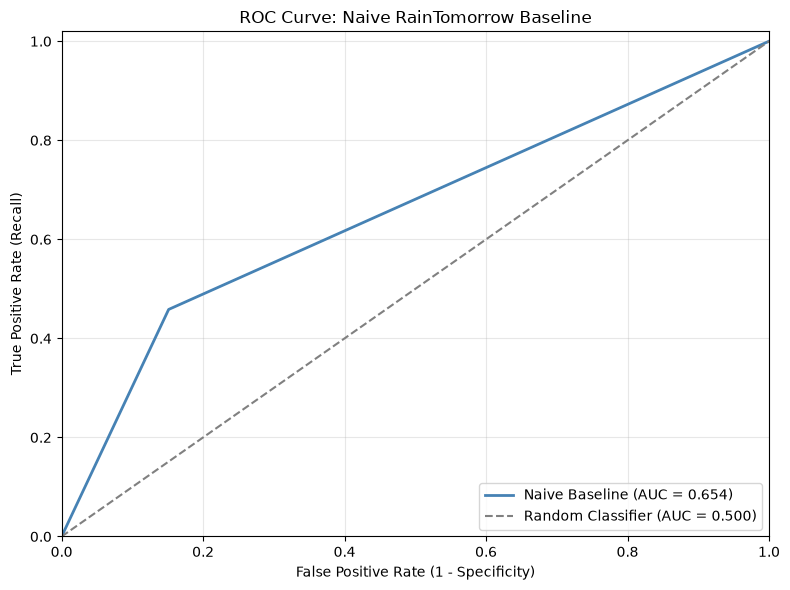

ROC-AUC: 0.6536


In [ ]:
# reciever operating chatacterisnt (roc) curve (we can continue to add to this visual once we do the Random forests)
y_true = np.asarray(y_val_enc).ravel()
y_score = np.asarray(X_val_enc["RainToday"]).ravel()

# calc roc curve
fpr, tpr, thresholds = roc_curve(y_true, y_score)

# calc area under curve 
roc_auc = auc(fpr, tpr)

# plot roc curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    color="steelblue",
    linewidth=2,
    label=f"Naive Baseline (AUC = {roc_auc:.3f})"
)

# reference line
plt.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--",
    label="Random Classifier (AUC = 0.500)"
)

plt.title("ROC Curve: Naive RainTomorrow Baseline")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc:.4f}")

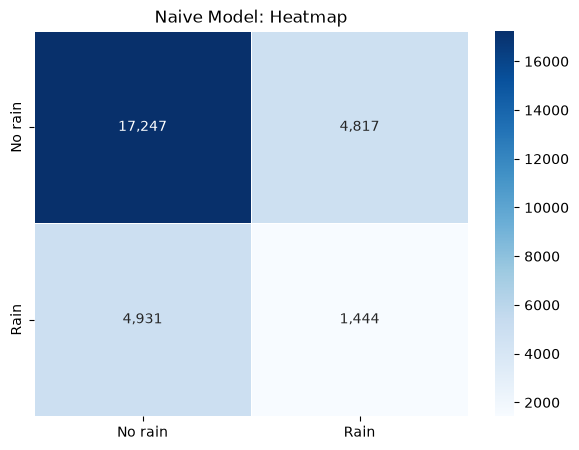

In [41]:
# confusion matrox - baseline
y_pred_string = np.where(y_pred == 1, "Yes", "No")
cm = confusion_matrix(
    y_test,
    y_pred_string,
    labels=["No", "Yes"] 
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt=",d",
    cmap="Blues",
    xticklabels=["No rain", "Rain"],
    yticklabels=["No rain", "Rain"],
    linewidths=0.5
)
plt.title("Naive Model: Heatmap")
plt.show()